# E-Commerce Sales & Customer Analytics

## 1. Data Loading & Initial Inspection
* **Objective:** Analyze e-commerce transaction records to identify key sales drivers, customer segment behavior, and geographical trends.
* **Setup & Ingestion:** Imported core analysis libraries (`pandas`, `numpy`) and loaded the dataset (`df.head()`) to inspect the initial schema and columns[span_1](start_span)[span_1](end_span).

In [434]:
import numpy as np
import pandas as pd 
from datetime import datetime 
pd.set_option('display.max_columns', None)

from IPython.core.interactiveshell import InteractiveShell

InteractiveShell.ast_node_interactivity = "all"
df=pd.read_csv(r"C:\Users\saifa\OneDrive\Desktop\PROJECTS\E commerce.csv")
df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,8/28/2025,2003,4,10,Gateway,Completed,36,Qom,3/5/2024,Regular,USB-C Cable,Accessories,9,32,32
1,500002,107935,5/31/2024,2014,1,10,Wallet,Completed,49,Kerman,6/4/2025,Regular,Backpack,Accessories,42,38,38
2,500003,105141,8/10/2025,2002,1,20,CardToCard,Completed,36,Tehran,10/19/2025,Regular,Mechanical Keyboard,Electronics,62,50,50
3,500004,108780,10/11/2024,2012,1,10,Gateway,Completed,45,Shiraz,12/7/2023,Regular,Office Chair,Home Office,180,162,162
4,500005,101187,2/19/2024,2008,2,0,Gateway,Completed,24,Karaj,12/2/2023,Regular,Phone Case,Accessories,14,28,28


### 2. Data Loading & Overview

* **Dataset Dimensions:** The dataset contains **49,222 rows** and **17 columns**, representing various E-commerce transactional and customer details.
* **Data Quality Check:** Using `.isnull().sum()`, we verified that there are **no missing or null values** in the dataset.
* **Duplicates Check:** Verified that there are **no duplicate rows** using `.duplicated().sum()`.

In [233]:
df.shape
df.isnull().sum()
df.duplicated().sum()

(49222, 17)

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

0

### 3. Data Preprocessing & Date Formatting

* **Datetime Conversion:** Converted `OrderDate` and `SignupDate` columns from string format into actual pandas `datetime` objects using `pd.to_datetime()`.
* **Feature Engineering:** Extracted `month` (month name) and `year` from `OrderDate` to enable robust time-series aggregation and trend analysis.

In [235]:
df['OrderDate']=pd.to_datetime(df['OrderDate']) 
df['SignupDate']=pd.to_datetime(df['SignupDate'])
#as you see now all the string dates have been turned into actual datetimes 
df[['OrderDate','SignupDate']]

,OrderDate,SignupDate
0,2025-08-28,2024-03-05
1,2024-05-31,2025-06-04
2,2025-08-10,2025-10-19
3,2024-10-11,2023-12-07
4,2024-02-19,2023-12-02
...,...,...
49217,2025-04-30,2025-03-24
49218,2025-01-26,2024-03-08
49219,2026-04-13,2025-02-19
49220,2025-04-18,2025-08-11


In [397]:
df['month']=df['OrderDate'].dt.month_name()
df['year']=df['OrderDate'].dt.year
df[['month','year']]

,month,year
0,August,2025
1,May,2024
2,August,2025
3,October,2024
4,February,2024
...,...,...
49217,April,2025
49218,January,2025
49219,April,2026
49220,April,2025


### 4. Advanced Data Filtering & Conditional Queries

* **Geographical Filtering (Karaj Orders):** Filtered the dataset to isolate transactions from Karaj, revealing a total volume of **4,966 orders**.
* **Value-Based Filtering (High-Value Transactions):** Filtered orders based on value thresholds, identifying **960 premium orders** exceeding a value of 350.
* **Compound Filtering:** Successfully combined multiple conditions using boolean operators to extract precise, targeted subsets for deeper analysis.

In [456]:
df[df['City']=='Karaj'].value_counts().sum()

df[df['OrderValue']>350].value_counts().sum()

4966

960

In [ ]:
df[(df['City']=='Karaj') & (df['OrderValue']>350)] #this is how to add two conditions by using these () brackets 

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue,month,year
480,500489,102142,2024-07-14,2012,4,0,Gateway,Completed,60,Karaj,2023-02-14,Regular,Office Chair,Home Office,180,720,720,July,2024
835,500845,104620,2024-09-04,2009,5,0,CardToCard,Completed,61,Karaj,2025-10-12,Regular,Smart Watch,Wearables,120,600,600,September,2024
1654,501677,108413,2025-11-14,2019,2,5,Gateway,Completed,29,Karaj,2023-07-10,New,Tablet,Electronics,260,494,494,November,2025
2146,502180,102813,2024-10-14,2019,3,20,Gateway,Completed,27,Karaj,2024-10-05,Regular,Tablet,Electronics,260,624,624,October,2024
2156,502190,100382,2025-04-06,2012,5,5,Wallet,Completed,62,Karaj,2023-03-18,Regular,Office Chair,Home Office,180,855,855,April,2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47604,548360,105271,2024-06-13,2019,3,10,CardToCard,Completed,26,Karaj,2023-07-18,VIP,Tablet,Electronics,260,702,702,June,2024
48461,549229,103047,2025-10-25,2009,4,20,Wallet,Completed,52,Karaj,2025-11-15,New,Smart Watch,Wearables,120,384,384,October,2025
48577,549346,103946,2025-06-23,2019,2,5,Gateway,Completed,53,Karaj,2025-09-03,New,Tablet,Electronics,260,494,494,June,2025
49054,549831,104146,2024-11-25,2019,2,5,CardToCard,Completed,31,Karaj,2023-01-22,Regular,Tablet,Electronics,260,494,494,November,2024


### 5. Statistical Analysis & Customer Segmentation

* **Order Value Statistics:** Calculated the aggregate metrics for `OrderValue`, showing a mean average of **~69.99**, with a maximum peak value of **1,300** and a minimum value of **-170**.
* **Customer Segment Distribution:** Analyzed customer types using `.value_counts()`, revealing that **Regular customers** are the most dominant segment, generating a total of **27,296 orders**.

In [457]:
df.agg({'OrderValue':['mean','max','min']}) 

,OrderValue
mean,69.985576
max,1300.000000
min,-170.000000


In [458]:
df['CustomerSegment'].value_counts() 

CustomerSegment
Regular    27296
New        17056
VIP         4870
Name: count, dtype: int64

### 6. Sales Performance & Aggregation Analysis

* **Customer Segment Sales:** Grouped sales by customer types, showing that **Regular customers** achieved the highest total revenue at **1,914**,

* **Product Category Sales:** Analyzed revenue across categories, revealing that **Electronics** generated the highest sales volume at **1,751**,

* **Temporal Sales Trends:** Aggregated sales by month and year, identifying **May 2025** as the peak period with the highest total sales of **130,607**
 
* **Geographical Sales Distribution:** Grouped revenue by city, proving that **Tehran** leads the market significantly with the highest total sales of **963,907** 

In [242]:
cust_sales=df.groupby('CustomerSegment')['Sales'].sum().sort_values(ascending=False) 
cust_sales  # as you see the regulat customers made the highest sales with 1914854 

CustomerSegment
Regular    1914854
New        1196104
VIP         333872
Name: Sales, dtype: int64

In [243]:
cat_sales=df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
cat_sales 
#as you the 'Electronics' category stuff was the highest in sales with 1751037

Category
Electronics    1751037
Accessories     553023
Home Office     446065
Wearables       429450
Gaming          198037
Stationery       67218
Name: Sales, dtype: int64

In [396]:
sales_date=df.groupby(['month','year'])['Sales'].sum().sort_values(ascending=False)
sales_date #as you see may 2025 is the highest in sales

month      year
May        2025    130607
January    2026    130550
August     2024    129987
July       2024    128689
March      2024    128150
June       2025    126269
December   2024    125897
November   2025    125300
October    2025    124299
May        2024    123683
January    2024    121893
November   2024    121208
August     2025    120441
September  2025    119935
July       2025    119743
March      2025    119432
January    2025    118487
October    2024    117260
June       2024    116784
September  2024    115943
April      2024    115941
December   2025    115790
April      2025    115278
February   2024    114664
           2025    108609
May        2026     85986
April      2026     85706
March      2026     84082
June       2026     79085
February   2026     75132
Name: Sales, dtype: int64

In [ ]:
sales_city=df.groupby('City')['Sales'].sum().sort_values(ascending=False)

sales_city

City
Tehran     963907
Mashhad    438112
Karaj      350173
Isfahan    334531
Shiraz     310775
Tabriz     292074
Ahvaz      211055
Rasht      205882
Kerman     175171
Qom        163150
Name: Sales, dtype: int64

### 7. Data Visualization & Insights

* **Visualization Setup:** Utilized `matplotlib` to build custom-styled bar charts with clear data labels for enhanced visual storytelling.

* **Customer Segment Sales Chart:** Plotted total revenue by customer types, highlighting that **Regular customers** massively lead the market by generating the highest revenue at **1,914,854**.

* **Product Category Sales Chart:** Plotted revenue across product categories, highlighting that **Electronics** overwhelmingly leads total sales at **1,751,037**, far outperforming Accessories and other categories.

* **Temporal Sales Trends Chart (`Month & Year`):** Utilized a horizontal bar chart (`plt.barh`) to visualize sales distribution across months and years, clearly identifying **May 2025** as the peak sales period leading the timeline.

* **Geographical Sales Distribution Chart:** Plotted revenue across cities using a vertical bar chart, demonstrating that **Tehran** dominates the market significantly with total sales of **963,907**, leading ahead of Mashhad and Karaj[span_1](start_span)[span_1](end_span).

<Figure size 800x500 with 0 Axes>

Text(0.0, 1944854, '1,914,854')

Text(1.0, 1226104, '1,196,104')

Text(2.0, 363872, '333,872')

Text(0.5, 1.0, 'Total Sales per Customer Type')

Text(0.5, 0, 'Customer Type')

Text(0, 0.5, 'Total Sales')

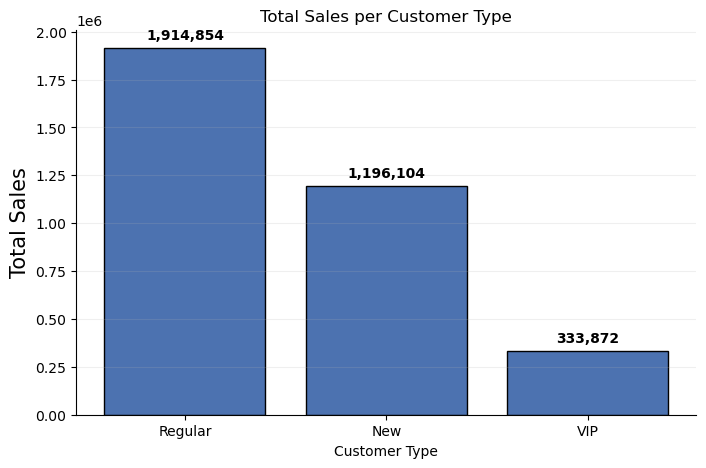

In [459]:
cust=cust_sales.index
cs=cust_sales.values

import matplotlib.pyplot as plt 
plt.figure(figsize=(8,5))

bars=plt.bar(cust,cs,color='#4C72B0',edgecolor='black')

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 30000,
             f'{int(height):,}',  # تنسيق الرقم بفاصل الآلاف
             ha='center', va='bottom', fontsize=10, fontweight='bold')
   
plt.title('Total Sales per Customer Type')
plt.xlabel('Customer Type',fontsize=10)
plt.ylabel('Total Sales',fontsize=15)


plt.grid(axis='y',alpha=0.2)
plt.show()


<Figure size 800x500 with 0 Axes>

Text(0.0, 1781037, '1,751,037')

Text(1.0, 583023, '553,023')

Text(2.0, 476065, '446,065')

Text(3.0, 459450, '429,450')

Text(4.0, 228037, '198,037')

Text(5.0, 97218, '67,218')

Text(0.5, 1.0, 'Total Sales Per Category')

Text(0.5, 0, 'Category')

Text(0, 0.5, 'Total Sales($)')

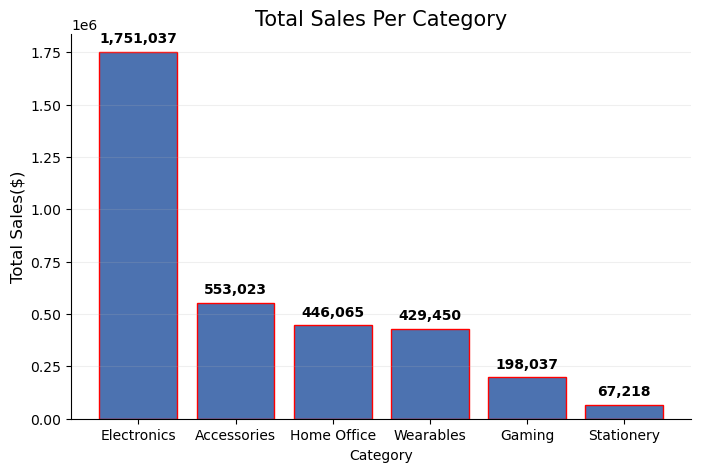

In [460]:
cat=cat_sales.index
sca=cat_sales.values

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

sat=plt.bar(cat,sca,color='#4C72B0',edgecolor='red')

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

for bar in sat:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 30000,
             f'{int(height):,}',  # تنسيق الرقم بفاصل الآلاف
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Total Sales Per Category',fontsize=15)
plt.xlabel('Category',fontsize=10)
plt.ylabel('Total Sales($)',fontsize=12)

plt.grid(axis='y',alpha=0.2)
plt.show()

<Figure size 1200x1000 with 0 Axes>

Text(0.5, 0, 'Total Sales($)')

Text(0, 0.5, 'Date(Month,Year)')

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

<BarContainer object of 30 artists>

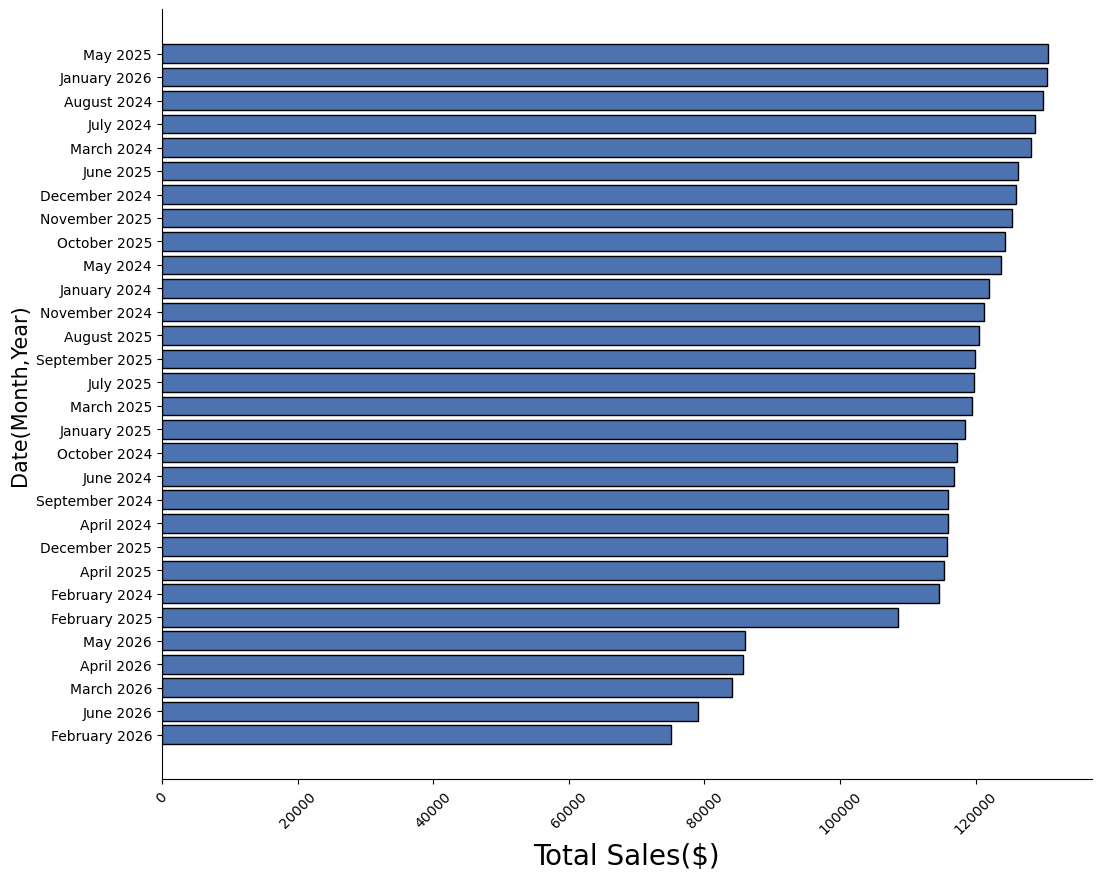

In [464]:
# Fix index tuple to format month and year labels for plotting
date=[f'{m} {y}' for m,y in sales_date.index]
sd=sales_date.values

import matplotlib.pyplot as plt
plt.figure(figsize=(12,10))

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False) 
plt.gca().invert_yaxis()

plt.xlabel('Total Sales($)',fontsize=20)
plt.ylabel('Date(Month,Year)',fontsize=15)
plt.xticks(rotation=45)

plt.barh(date,sd,color='#4C72B0',edgecolor='black')


Now let's plot the sales-city graph

<Figure size 1000x700 with 0 Axes>

Text(0.5, 1.0, 'Total Sales per City')

Text(0.5, 0, 'City')

Text(0, 0.5, 'Total Sales($)')

Text(0.0, 993907, '963,907')

Text(1.0, 468112, '438,112')

... (4 outputs left out)

Text(6.0, 241055, '211,055')

Text(7.0, 235882, '205,882')

Text(8.0, 205171, '175,171')

Text(9.0, 193150, '163,150')

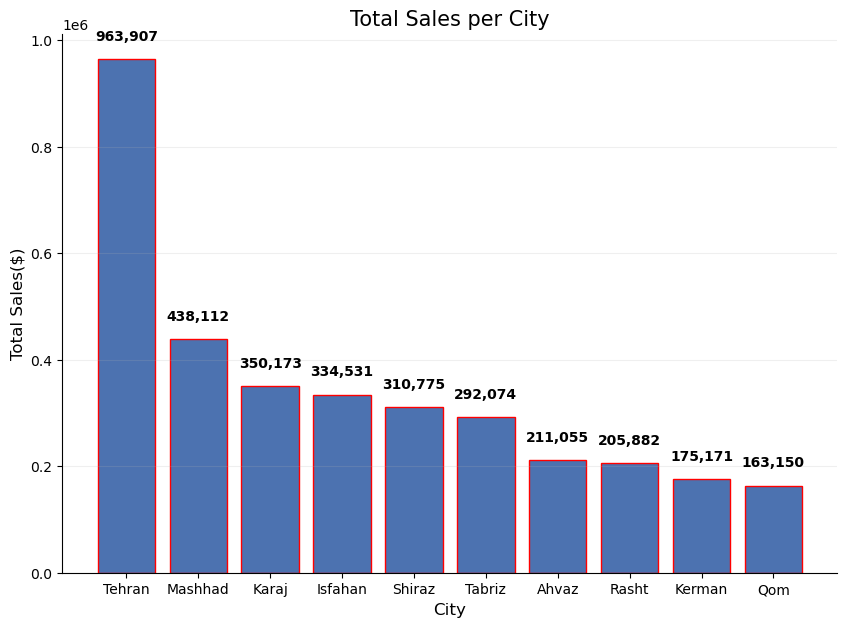

In [462]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.title('Total Sales per City',fontsize=15)
plt.xlabel('City',fontsize=12)
plt.ylabel('Total Sales($)',fontsize=12)


xy=plt.bar(sales_city.index,sales_city.values,color='#4C72B0',edgecolor='red')

for bar in xy:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 30000,
             f'{int(height):,}',  # تنسيق الرقم بفاصل الآلاف
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.grid(axis='y',alpha=0.2)
plt.show()

### 8. Conclusion & Key Business Insights

* **Dominant Customer Base:** Regular customers represent the backbone of the business, generating the highest volume of orders (27,296) and total revenue (1,914,854), proving strong long-term loyalty.
* **Top-Performing Product Category:** Electronics leads the product catalog significantly, pulling in the highest total sales (1,751,037) compared to all other categories.
* **Geographical Stronghold:** Tehran stands out as the primary revenue driver, outperforming all other cities with total sales reaching 963,907.
* **Peak Temporal Demand:** Sales momentum peaked notably in May 2025, indicating strong seasonal performance during that period.

**Strategic Recommendations:**
* Focus marketing campaigns and loyalty programs on retaining the **Regular customer segment** while designing targeted acquisition strategies for New and VIP customers.
* Prioritize inventory management and promotional campaigns around top-performing categories like **Electronics** and key markets like **Tehran** to maximize return on investment.